# Exploration et préparation des données DVF 2025

**Source :** Demandes de valeurs foncières (DVF), DGFiP, millésime 2025 (data.gouv.fr).

**Objectif :** préparer un jeu de données pour entraîner un modèle de prédiction du prix des biens immobiliers.


## 1. Import des bibliothèques

In [55]:
# Manipulation des données (pandas) et graphes (seaborn)

import pandas as pd
import seaborn as sn

## 2. Chargement des données

In [56]:
# Lecture du fichier DVF : séparateur '|', tout en texte pour préserver les zéros des codes
filepath="data/ValeursFoncieres-2025.txt"
df = pd.read_csv(filepath, sep="|", dtype=str)

## 3. Premier contact avec les données

In [57]:
pd.set_option("display.max_columns", None)

df.head()

,Identifiant de document,Reference document,1 Articles CGI,2 Articles CGI,3 Articles CGI,4 Articles CGI,5 Articles CGI,No disposition,Date mutation,Nature mutation,Valeur fonciere,No voie,B/T/Q,Type de voie,Code voie,Voie,Code postal,Commune,Code departement,Code commune,Prefixe de section,Section,No plan,No Volume,1er lot,Surface Carrez du 1er lot,2eme lot,Surface Carrez du 2eme lot,3eme lot,Surface Carrez du 3eme lot,4eme lot,Surface Carrez du 4eme lot,5eme lot,Surface Carrez du 5eme lot,Nombre de lots,Code type local,Type local,Identifiant local,Surface reelle bati,Nombre pieces principales,Nature culture,Nature culture speciale,Surface terrain
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,000001,07/01/2025,Vente,"468000,00",NaN,NaN,NaN,B078,FARGES,1550,FARGES,01,158,NaN,B,815,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,J,NaN,78
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,000001,07/01/2025,Vente,"468000,00",454,NaN,RUE,0090,DE LA REPUBLIQUE,1550,FARGES,01,158,NaN,B,910,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3,Dépendance,NaN,0,0,S,NaN,133
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,000001,07/01/2025,Vente,"468000,00",454,NaN,RUE,0090,DE LA REPUBLIQUE,1550,FARGES,01,158,NaN,B,910,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,Maison,NaN,111,5,S,NaN,133
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,000001,06/01/2025,Vente,"180000,00",NaN,NaN,NaN,B158,LE VILLAGE,1200,MONTANGES,01,257,NaN,AC,334,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,S,NaN,46
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,000001,06/01/2025,Vente,"180000,00",NaN,NaN,NaN,B158,LE VILLAGE,1200,MONTANGES,01,257,NaN,AC,338,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,J,NaN,17


**Constat (head) :**
- Plusieurs lignes partagent la même date, le même n° de disposition et la même valeur foncière (lignes 0 à 2 : 468 000 €). Une ligne ne correspond donc pas à une vente mais à un élément de la vente (parcelle, maison, dépendance).
- Les montants utilisent une virgule décimale (468000,00).
- Plusieurs colonnes semblent entièrement vides (articles CGI, identifiants).

In [58]:
# Dimensions : (nombre de lignes, nombre de colonnes)

df.shape

(3793113, 43)

In [59]:
# Types des colonnes

df.dtypes

,0
Identifiant de document,object
Reference document,object
1 Articles CGI,object
2 Articles CGI,object
3 Articles CGI,object
4 Articles CGI,object
5 Articles CGI,object
No disposition,object
Date mutation,object
Nature mutation,object


**Constat (dtypes) :** toutes les colonnes sont de type object (texte). C'est la conséquence attendue de dtype=str. Cette sortie ne renseigne donc pas sur le type réel des données : il faut regarder le contenu des colonnes.

In [60]:
# Exemples de valeurs pour identifier le format des montants

df["Valeur fonciere"].unique()[:20]

array(['468000,00', '180000,00', '490000,00', '183000,00', '295000,00',
       '543510,00', '131937,30', '173000,00', '425000,00', '1165000,00',
       '630000,00', '6570,00', '314000,00', '414665,00', '136000,00',
       '925000,00', '79000,00', '274000,00', '259000,00', '64000,00'],
      dtype=object)

**Constat :** la valeur foncière est écrite avec une **virgule** comme séparateur décimal ('468000,00').

## 4. Contrôle du format des codes géographiques

In [61]:
# Répartition des longueurs du code postal (attendu : 5 caractères)

df['Code postal'].str.len().value_counts()

,count
Code postal,
5.0,3489550
4.0,285246


**Constat (code postal) :**
- 285 246 codes ont **4 caractères au lieu de 5**.
- L'index est en décimal (5.0, 4.0) : c'est le signe de valeurs manquantes. La somme des deux lignes (3 774 796) est inférieure au nombre total de lignes.

In [62]:
# Répartition des longueurs du code département

df['Code departement'].str.len().value_counts()

,count
Code departement,
2,3759701
3,33412


**Constat (code département) :**
- 2 caractères pour la métropole
- 3 caractères pour 33 412 lignes : ce sont les **départements d'outre-mer** (971 Guadeloupe, 972 Martinique, 973 Guyane, 974 La Réunion).


In [63]:
# Répartition des longueurs du code commune

df['Code commune'].str.len().value_counts()

,count
Code commune,
3,2599875
2,1043336
1,149902


**Constat (code commune) :** le code fait 1, 2 ou 3 caractères, donc les zéros initiaux ont été perdus.

- Métropole : 2 caractères de département + **3** de commune.
- Outre-mer : 3 caractères de département + **2** de commune.


**Contrôle des départements à 3 caractères :**

In [64]:
# Affichage des départements à 3 caractères

df[df['Code departement'].str.len()==3]['Code departement'].value_counts()

,count
Code departement,
974,15718
971,6483
972,6386
973,4825


In [65]:
# Nombre de valeurs manquantes par colonne

df.isna().sum()

,0
Identifiant de document,3793113
Reference document,3793113
1 Articles CGI,3793113
2 Articles CGI,3793113
3 Articles CGI,3793113
4 Articles CGI,3793113
5 Articles CGI,3793113
No disposition,0
Date mutation,0
Nature mutation,0


**Constat :**
- **8 colonnes sont vides à 100 %** : Identifiant de document, Reference document, 1 à 5 Articles CGI, Identifiant local.
- D'autres colonnes sont majoritairements vides : B/T/Q, Prefixe de section, No Volume, lots 3 à 5, Surfaces Carrez des lots 2 à 5, Nature culture speciale.

- Valeur fonciere : 50 484 valeurs manquantes.


## 6. Conversion de la valeur foncière en nombre

In [66]:
# Conversion en nombre : virgule -> point, puis to_numeric (NaN si non convertible)

df['Valeur fonciere']=pd.to_numeric(df['Valeur fonciere'].str.replace(",", ".", regex=False), errors='coerce')

In [67]:
# Valeurs manquantes après conversion

df.isna().sum()

,0
Identifiant de document,3793113
Reference document,3793113
1 Articles CGI,3793113
2 Articles CGI,3793113
3 Articles CGI,3793113
4 Articles CGI,3793113
5 Articles CGI,3793113
No disposition,0
Date mutation,0
Nature mutation,0


**Constat :** Valeur fonciere compte **50 484 valeurs manquantes avant et après** la conversion. La conversion n'a perdu aucune donnée : les NaN présents correspondent à des valeurs réellement absentes du fichier source.

## 7. Première description de la cible

In [68]:
df['Valeur fonciere'].describe()

,Valeur fonciere
count,3.742629e+06
mean,8.646143e+05
std,7.594326e+06
min,1.000000e-01
25%,7.000000e+04
50%,1.670000e+05
75%,3.060000e+05
max,6.950000e+08


**Constat :**
- Minimum de **0,10 €** : des prix symboliques ou des erreurs de saisie, qui ne correspondent pas à des prix de marché.
- Médiane de 167 000 € mais moyenne de 864 614 €, soit environ **5 fois la médiane**, et maximum de 695 M€. La distribution est très asymétrique, tirée par quelques montants extrêmes.



## 8. Occupation mémoire

In [69]:
df.memory_usage(deep=True).sum()

np.int64(6603769944)

**Constat :** le DataFrame occupe environ **6,6 Go** en mémoire. Ce volume ralentit chaque opération et peut saturer la RAM.


## 9. Correction des codes géographiques
### 9.1 Code postal

In [70]:
# Ajout des zéros manquants au code postal, puis contrôle des longueurs

df['Code postal'] = df['Code postal'].str.zfill(5)
df['Code postal'].str.len().value_counts(dropna=False)

,count
Code postal,
5.0,3774796
NaN,18317


**Constat :** après correction, tous les codes postaux renseignés font 5 caractères. Les 18 317 `NaN` sont conservés tels quels.

### 9.2 Construction du code commune INSEE (5 caractères)
Le code INSEE identifie une commune de façon unique au niveau national.

In [71]:
import numpy as np

dep = df['Code departement']
com = df['Code commune']

df['code_insee'] = np.where(
    dep.str.len() == 3,          # condition : département d'outre-mer ?
    dep + com.str.zfill(2),      # si oui : 971 + 17  -> 97117
    dep + com.str.zfill(3)       # sinon  : 01  + 158 -> 01158
)

In [72]:
# 1. Tous les codes doivent faire 5 caractères
df['code_insee'].str.len().value_counts(dropna=False)



,count
code_insee,
5,3793113


In [73]:
# 2. Contrôle sur des communes connues (métropole et outre-mer)
df[df['Commune'].isin(['FARGES', 'LE MOULE', 'LES ABYMES'])] \
    .drop_duplicates('Commune')[['Commune', 'code_insee']]

,Commune,code_insee
0,FARGES,01158
3673511,LE MOULE,97117
3673512,LES ABYMES,97101


**Constat :** les codes obtenus correspondent aux codes INSEE officiels

In [74]:
df['code_insee'].nunique()

32712

**Constat :** **32 712 communes distinctes**.

**Conséquence pour la modélisation :** un encodage one-hot créerait 32 712 colonnes, ce qui est inutilisable. Ce chiffre justifie un **encodage par la cible** (prix médian de la commune, calculé sur le jeu d'entraînement uniquement et lissé pour les communes avec peu de ventes) ou un encodage par fréquence.

In [75]:
# Bibliothèques supplémentaires pour les graphes

import matplotlib.pyplot as plt
import numpy as np

## 10. Suppression des colonnes inutiles
### 10.1 Taux de valeurs manquantes par colonne (graphe)

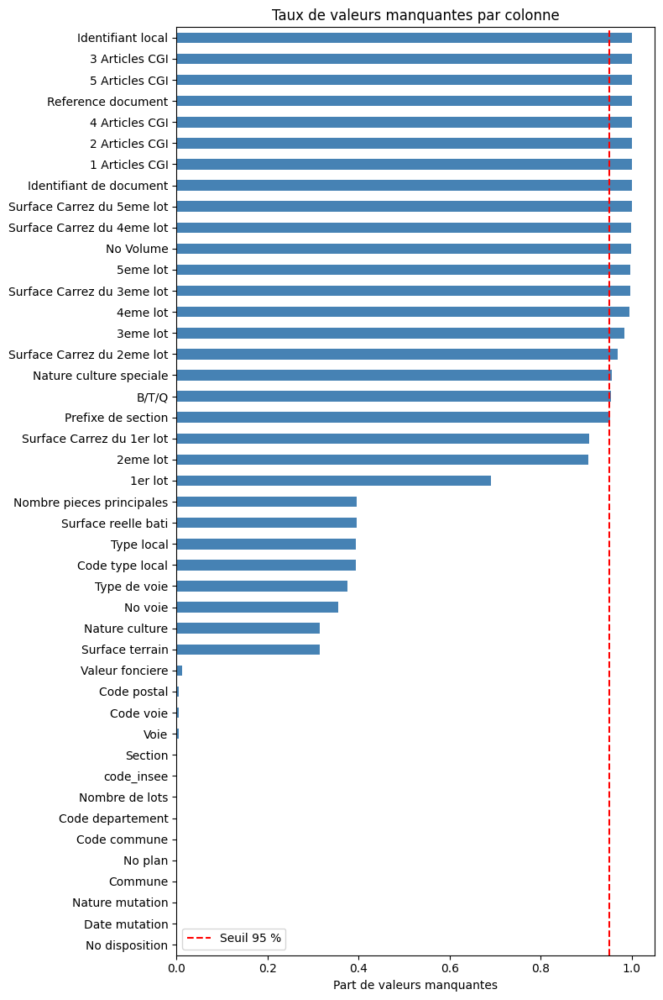

In [76]:
# Part de valeurs manquantes par colonne (entre 0 et 1), triée
taux_na = df.isna().mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 12))
taux_na.plot.barh(ax=ax, color='steelblue')
ax.axvline(0.95, color='red', linestyle='--', label='Seuil 95 %')
ax.set_xlabel('Part de valeurs manquantes')
ax.set_title('Taux de valeurs manquantes par colonne')
ax.legend()
plt.tight_layout()
plt.show()

**Constat :** 19 colonnes dépassent 95 % de valeurs manquantes, dont 8 vides à 100 % (identifiants, articles CGI). Juste sous le seuil : Surface Carrez du 1er lot (90,6 %), 2eme lot (90,4 %) et 1er lot (69 %). Les colonnes liées au bâti (Surface reelle bati, Type local …) sont absentes à environ 40 % : ce sont des parcelles sans bâtiment, pas des données perdues.

In [77]:
# Liste des colonnes au-delà du seuil de 95 %
SEUIL_NA = 0.95
cols_a_supprimer = taux_na[taux_na > SEUIL_NA].index.tolist()
print(len(cols_a_supprimer), 'colonnes supprimées :')
print(cols_a_supprimer)

df = df.drop(columns=cols_a_supprimer)
df.shape

19 colonnes supprimées :
['Prefixe de section', 'B/T/Q', 'Nature culture speciale', 'Surface Carrez du 2eme lot', '3eme lot', '4eme lot', 'Surface Carrez du 3eme lot', '5eme lot', 'No Volume', 'Surface Carrez du 4eme lot', 'Surface Carrez du 5eme lot', 'Identifiant de document', '1 Articles CGI', '2 Articles CGI', '4 Articles CGI', 'Reference document', '5 Articles CGI', '3 Articles CGI', 'Identifiant local']


(3793113, 25)

**Décision :** suppression des 19 colonnes au-delà du seuil. Le DataFrame passe de 43 à 25 colonnes (la colonne code_insee ayant été ajoutée).

### 10.2 Colonnes d'adresse

In [78]:
# Nombre de valeurs distinctes des colonnes d'adresse
cols_adresse = ['No voie', 'Type de voie', 'Code voie', 'Voie']
df[cols_adresse].nunique()

,0
No voie,7339
Type de voie,138
Code voie,16313
Voie,455906


**Constat :** 455 906 noms de voie et 16 313 codes de voie distincts. Ces valeurs sont presque uniques par bien et ne se généralisent pas pour un modèle.

In [79]:
# Suppression des colonnes d'adresse (décision à justifier par la sortie ci-dessus)
df = df.drop(columns=cols_adresse)
df.shape

(3793113, 21)

**Décision :** suppression des 4 colonnes d'adresse. La localisation est portée par code_insee. Le DataFrame passe à 21 colonnes.

## 11. Conversion des autres colonnes
### 11.1 Colonnes numériques

In [80]:
# Colonnes numériques encore présentes après la suppression
cols_num = [c for c in ['Surface reelle bati', 'Nombre pieces principales', 'Surface terrain',
                        'Nombre de lots', 'Surface Carrez du 1er lot']
            if c in df.columns]

controle = []
for col in cols_num:
    na_avant = df[col].isna().sum()
    df[col] = pd.to_numeric(df[col].str.replace(',', '.', regex=False), errors='coerce')
    na_apres = df[col].isna().sum()
    controle.append({'colonne': col, 'NaN avant': na_avant, 'NaN après': na_apres,
                     'NaN créés': na_apres - na_avant})

pd.DataFrame(controle)

,colonne,NaN avant,NaN après,NaN créés
0,Surface reelle bati,1499963,1499963,0
1,Nombre pieces principales,1499963,1499963,0
2,Surface terrain,1191147,1191147,0
3,Nombre de lots,0,0,0
4,Surface Carrez du 1er lot,3437171,3437171,0


**Constat :** aucune valeur manquante créée par la conversion (colonne « NaN créés » à 0). Les 5 colonnes numériques sont converties sans perte.

### 11.2 Date
`format='%d/%m/%Y'` est indispensable

In [81]:
# Conversion de la date et contrôle de la période couverte
df['Date mutation'] = pd.to_datetime(df['Date mutation'], format='%d/%m/%Y', errors='coerce')
print('Dates non converties :', df['Date mutation'].isna().sum())
print('Période :', df['Date mutation'].min(), '->', df['Date mutation'].max())

Dates non converties : 0
Période : 2025-01-01 00:00:00 -> 2025-12-31 00:00:00


**Constat :** toutes les dates sont converties. Elles couvrent bien l'année 2025, du 1er janvier au 31 décembre.

### 11.3 Colonnes catégorielles et gain mémoire

In [82]:
# Nombre de modalités des colonnes candidates
cols_cat = [c for c in ['Nature mutation', 'Type local', 'Code type local', 'Nature culture',
                        'Code departement'] if c in df.columns]

print(cols_cat)
df[cols_cat].nunique()

['Nature mutation', 'Type local', 'Code type local', 'Nature culture', 'Code departement']


,0
Nature mutation,6
Type local,4
Code type local,4
Nature culture,27
Code departement,97


**Constat :** les colonnes candidates ont peu de modalités (de 4 à 97) pour 3,8 millions de lignes. Le type `category` est donc adapté.

In [83]:
# Mémoire avant / après conversion en category (en Go)
mem_avant = df.memory_usage(deep=True).sum() / 1e9
df[cols_cat] = df[cols_cat].astype('category')
mem_apres = df.memory_usage(deep=True).sum() / 1e9
print(f'Mémoire avant : {mem_avant:.2f} Go | après : {mem_apres:.2f} Go | gain : {1 - mem_apres/mem_avant:.0%}')

Mémoire avant : 2.86 Go | après : 1.93 Go | gain : 32%


**Constat / Décision :** −32 % de mémoire avec category (2,86 → 1,93 Go).

## 12. Regroupement des lignes par vente
### 12.1 Construction d'un identifiant de vente

In [84]:
# Retrait des lignes sans valeur foncière
print('Lignes sans valeur foncière retirées :', df['Valeur fonciere'].isna().sum())
df = df.dropna(subset=['Valeur fonciere'])

# Identifiant de vente : un numéro par combinaison unique de ces 4 colonnes
cle_vente = ['Date mutation', 'No disposition', 'Valeur fonciere', 'code_insee']
df['id_mutation'] = df.groupby(cle_vente, sort=False, observed=True).ngroup()

print('Lignes :', len(df), '| Ventes :', df['id_mutation'].nunique())

Lignes sans valeur foncière retirées : 50484
Lignes : 3742629 | Ventes : 1347969


**Constat :** 50 484 lignes sans prix sont retirées, car sans cible elles sont inutilisables. Les 3 742 629 lignes restantes correspondent à **1 347 969 ventes**.

,0
count,1.347969e+06
mean,2.776495e+00
std,8.709059e+00
min,1.000000e+00
25%,1.000000e+00
50%,2.000000e+00
75%,3.000000e+00
max,5.799000e+03


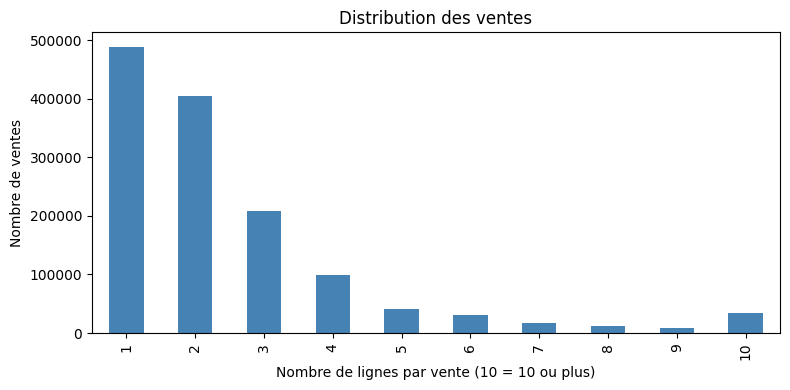

In [85]:
# Nombre de lignes par vente
lignes_par_vente = df.groupby('id_mutation').size()
display(lignes_par_vente.describe())

fig, ax = plt.subplots(figsize=(8, 4))
lignes_par_vente.clip(upper=10).value_counts().sort_index().plot.bar(ax=ax, color='steelblue')
ax.set_xlabel('Nombre de lignes par vente (10 = 10 ou plus)')
ax.set_ylabel('Nombre de ventes')
ax.set_title('Distribution des ventes')
plt.tight_layout()
plt.show()

**Décision :** regrouper les lignes pour obtenir une ligne par vente avant toute modélisation.

### 12.2 Piège : les lignes en double à l'intérieur d'une vente

In [86]:
# Locaux : un local est identifié par sa vente, sa parcelle, son type, sa surface, ses pièces et son lot
cle_local = ['id_mutation', 'Section', 'No plan', 'Type local',
             'Surface reelle bati', 'Nombre pieces principales', '1er lot']
cle_local = [c for c in cle_local if c in df.columns]
locaux = df[df['Type local'].notna()]

# Groupes de lignes considérés comme un même local par la clé
doublons = locaux[locaux.duplicated(cle_local, keep=False)]
groupes = doublons.groupby(cle_local, dropna=False, observed=True)

# Pour chaque autre colonne : part des groupes où sa valeur change
autres_cols = [c for c in doublons.columns if c not in cle_local]
varie = groupes[autres_cols].nunique(dropna=False).gt(1)
display(varie.mean().sort_values(ascending=False).head(5))

# Groupes identiques sur toutes les colonnes : de quel type de local s'agit-il ?
identiques = varie[~varie.any(axis=1)].reset_index()
print(len(identiques), 'groupes identiques sur', len(varie))
identiques['Type local'].value_counts()

,0
Nature culture,0.556191
Surface terrain,0.553958
2eme lot,0.002033
Nombre de lots,0.001943
Nature mutation,0.000102


107724 groupes identiques sur 245468


,count
Type local,
Dépendance,91169
Appartement,12835
Maison,2242
Local industriel. commercial ou assimilé,1478


**Constat :**
- 245 468 groupes de lignes sont considérés comme un même local par cle_local.
- Dans **55,6 %** d'entre eux, seuls Nature culture et Surface terrain changent. C'est le même local, répété une fois par type de terrain de la parcelle : le dédoublonnage est justifié.
- **107 724 groupes** sont identiques sur toutes les colonnes : 85 % de dépendances (surface nulle, donc sans effet sur les surfaces), 12 % d'appartements, 2 % de maisons.

In [87]:
ident_logement = identiques[identiques['Type local'].isin(['Appartement', 'Maison'])]
ident_logement['1er lot'].isna().mean()

np.float64(0.934337069708828)

**Constat :** 93 % des maisons et appartements identiques n'ont pas de numéro de lot. On ne peut donc pas savoir s'il s'agit d'un même logement répété ou de logements distincts identiques. Ces ventes sont marquées comme ambiguës en 13.1.

In [88]:
# Dédoublonnage des locaux et des terrains avant de les additionner
locaux_uniques = locaux.drop_duplicates(cle_local)
print(f'Locaux : {len(locaux)} lignes -> {len(locaux_uniques)} uniques '
      f'({1 - len(locaux_uniques)/len(locaux):.1%} de doublons)')

cle_terrain = ['id_mutation', 'Section', 'No plan', 'Nature culture', 'Surface terrain']
terrains = df[df['Surface terrain'].notna()]
terrains_uniques = terrains.drop_duplicates(cle_terrain)
print(f'Terrains : {len(terrains)} lignes -> {len(terrains_uniques)} uniques '
      f'({1 - len(terrains_uniques)/len(terrains):.1%} de doublons)')

Locaux : 2273501 lignes -> 1837315 uniques (19.2% de doublons)
Terrains : 2556630 lignes -> 1994583 uniques (22.0% de doublons)


**Constat / Décision :** 19,2 % des lignes de locaux et 22 % des lignes de terrain sont des doublons. Sans dédoublonnage, les surfaces auraient été surestimées. Les sommes de l'étape suivante portent donc sur les lignes uniques.

**Limite :** les dépendances identiques d'une même parcelle sont fusionnées, ce qui rend nb_dépendance sous-estimé. Nous utiliserons une variable de présence (0/1).

### 12.3 Agrégation : une ligne par vente

In [89]:
# a) Informations communes à toute la vente
ventes = df.groupby('id_mutation').agg(
    date=('Date mutation', 'first'),
    nature_mutation=('Nature mutation', 'first'),
    valeur_fonciere=('Valeur fonciere', 'first'),
    code_insee=('code_insee', 'first'),
    code_departement=('Code departement', 'first'),
    nb_lignes=('Valeur fonciere', 'size'),
)

# b) Nombre de locaux de chaque type dans la vente
nb_locaux = (locaux_uniques.groupby(['id_mutation', 'Type local'], observed=True)
             .size().unstack(fill_value=0))

print(nb_locaux)

Type local   Appartement  Dépendance  \
id_mutation                            
0                      0           1   
1                      1           0   
2                      0           1   
3                      1           2   
4                      0           0   
...                  ...         ...   
1347964                1           1   
1347965                1           1   
1347966                1           1   
1347967                1           2   
1347968                0           0   

Type local   Local industriel. commercial ou assimilé  Maison  
id_mutation                                                    
0                                                   0       1  
1                                                   0       0  
2                                                   0       1  
3                                                   0       0  
4                                                   0       1  
...                            

In [90]:


nb_locaux.columns = ['nb_' + str(c).split('.')[0].split(' ')[0].lower() for c in nb_locaux.columns]

# c) Surface habitable et pièces (maisons + appartements uniquement)
habitat = locaux_uniques[locaux_uniques['Type local'].isin(['Maison', 'Appartement'])]
surf_hab = habitat.groupby('id_mutation').agg(
    surface_bati=('Surface reelle bati', 'sum'),
    nb_pieces=('Nombre pieces principales', 'sum'),
)

# d) Surface de terrain totale
surf_terrain = terrains_uniques.groupby('id_mutation')['Surface terrain'].sum().rename('surface_terrain')

# Assemblage
ventes = (ventes.join(nb_locaux).join(surf_hab).join(surf_terrain))
cols_nb = [c for c in ventes.columns if c.startswith('nb_') and c != 'nb_lignes']
ventes[cols_nb + ['surface_terrain']] = ventes[cols_nb + ['surface_terrain']].fillna(0)

print(ventes.shape)
ventes.head()

(1347969, 13)


,date,nature_mutation,valeur_fonciere,code_insee,code_departement,nb_lignes,nb_appartement,nb_dépendance,nb_local,nb_maison,surface_bati,nb_pieces,surface_terrain
id_mutation,,,,,,,,,,,,,
0,2025-01-07,Vente,468000.0,01158,01,3,0.0,1.0,0.0,1.0,111.0,5.0,211.0
1,2025-01-06,Vente,180000.0,01257,01,3,1.0,0.0,0.0,0.0,87.0,4.0,139.0
2,2025-01-06,Vente,490000.0,01065,01,12,0.0,1.0,0.0,1.0,190.0,6.0,3637.0
3,2025-01-09,Vente,183000.0,01173,01,3,1.0,2.0,0.0,0.0,35.0,2.0,0.0
4,2025-01-07,Vente,295000.0,01028,01,3,0.0,0.0,0.0,1.0,95.0,2.0,1305.0


**Constat :** on obtient une ligne par vente (1 347 969 lignes, 13 colonnes).

## 13. Catégorisation des ventes et choix des natures de mutation
### 13.1 Type de vente

In [91]:
# Classement de chaque vente selon les locaux qu'elle contient
m, a = ventes.get('nb_maison', 0), ventes.get('nb_appartement', 0)
loc_com = ventes.get('nb_local', 0)
logements = m + a

conditions = [
    (m == 1) & (a == 0) & (loc_com == 0),
    (a == 1) & (m == 0) & (loc_com == 0),
    (logements >= 2) & (loc_com == 0),
    (logements == 0) & (loc_com > 0),
    (logements == 0) & (loc_com == 0),
]
choix = ['Maison seule', 'Appartement seul', 'Plusieurs logements', 'Local commercial', 'Sans logement']
ventes['type_vente'] = np.select(conditions, choix, default='Mixte')
print(ventes['type_vente'])


id_mutation
0              Maison seule
1          Appartement seul
2              Maison seule
3          Appartement seul
4              Maison seule
                 ...       
1347964    Appartement seul
1347965    Appartement seul
1347966    Appartement seul
1347967    Appartement seul
1347968    Local commercial
Name: type_vente, Length: 1347969, dtype: object


In [92]:
# Prix au m² (uniquement si une surface habitable existe)
ventes['prix_m2'] = ventes['valeur_fonciere'] / ventes['surface_bati'].where(ventes['surface_bati'] > 0)

ventes['type_vente'].value_counts()

,count
type_vente,
Maison seule,465238
Sans logement,400198
Appartement seul,363836
Local commercial,51620
Plusieurs logements,44453
Mixte,22624


**Constat :** les ventes d'un seul logement dominent (465 238 maisons et 363 836 appartements). 400 198 ventes ne contiennent aucun logement (terrains, dépendances seules) : elles n'ont pas de surface habitable, donc pas de prix au m².

In [93]:
ventes_ambigues = ident_logement['id_mutation'].unique()
ventes['doublon_ambigu'] = ventes.index.isin(ventes_ambigues)
print(f"{ventes['doublon_ambigu'].sum()} ventes ambiguës ({ventes['doublon_ambigu'].mean():.2%})")

8850 ventes ambiguës (0.66%)


**Constat :** 8 850 ventes ambiguës, soit 0,66 % des ventes.

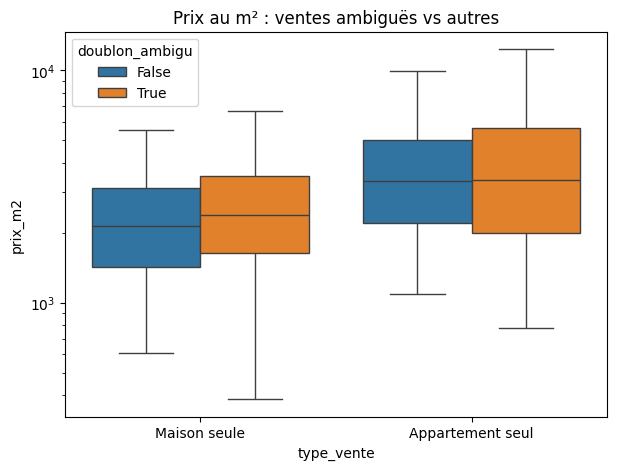

In [94]:
fig, ax = plt.subplots(figsize=(7, 5))
sn.boxplot(data=ventes[ventes['type_vente'].isin(['Maison seule', 'Appartement seul'])],
            x='type_vente', y='prix_m2', hue='doublon_ambigu',
            showfliers=False, whis=(5, 95), ax=ax)
ax.set_yscale('log')
ax.set_title('Prix au m² : ventes ambiguës vs autres')
plt.show()

**Constat :** les médianes du prix au m² sont proches entre ventes ambiguës et autres, à peine plus élevées pour les maisons ambiguës. Seule la dispersion est un peu plus large. L'hypothèse d'un prix au m² faussé (surface divisée par deux) **n'est pas confirmée** : ces lignes sont surtout de vrais doublons d'un même logement.


### 13.2 Prix au m² selon la nature de mutation

,count
nature_mutation,
Vente,1271607
Vente en l'état futur d'achèvement,51404
Echange,17642
Vente terrain à bâtir,4592
Adjudication,2640
Expropriation,84


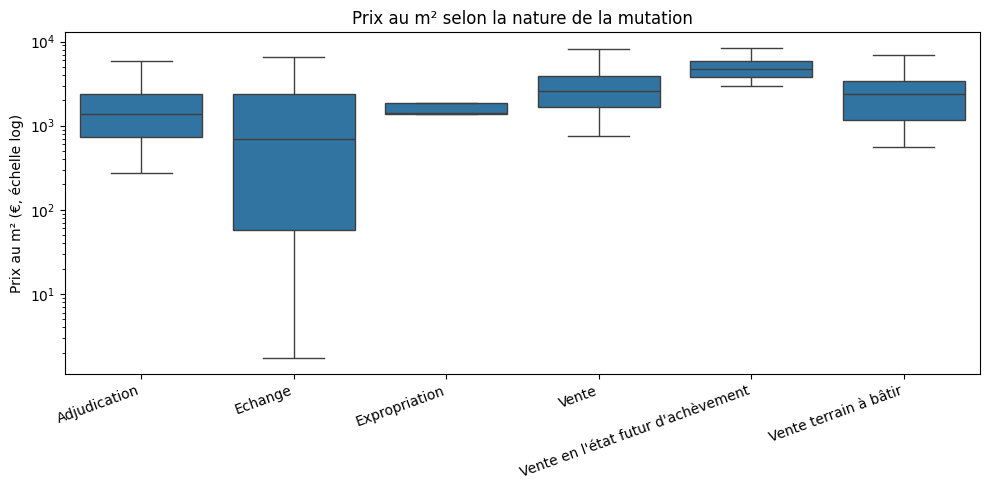

In [95]:
# Effectifs par nature de mutation
display(ventes['nature_mutation'].value_counts())

# Boxplot du prix au m², ventes d'un seul logement uniquement, échelle log
# (moustaches = 5e et 95e percentiles, plus lisibles en échelle log)
un_logement = ventes[ventes['type_vente'].isin(['Maison seule', 'Appartement seul'])]
fig, ax = plt.subplots(figsize=(10, 5))
sn.boxplot(data=un_logement, x='nature_mutation', y='prix_m2', ax=ax, showfliers=False, whis=(5, 95))
ax.set_yscale('log')
ax.set_xlabel('')
ax.set_ylabel('Prix au m² (€, échelle log)')
ax.set_title('Prix au m² selon la nature de la mutation')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

**Constat :**
- **Échange** : prix au m² très dispersé, jusqu'à quelques €/m². Pas de prix de marché, puisqu'il y a une contrepartie en nature.
- **Adjudication** (vente aux enchères) : médiane nettement plus basse.
- **Expropriation** : 84 ventes seulement, prix fixé par l'administration.
- **Vente terrain à bâtir** : hors du sujet du logement existant.
- **VEFA** (vente sur plan) : médiane plus élevée.

In [96]:
# Natures conservées
natures_gardees = ['Vente', "Vente en l'état futur d'achèvement"]
avant = len(ventes)
ventes = ventes[ventes['nature_mutation'].isin(natures_gardees)]
print(f'Ventes retirées : {avant - len(ventes)} ({1 - len(ventes)/avant:.1%})')

Ventes retirées : 24958 (1.9%)


**Décision :** on conserve Vente et VEFA, ce qui retire 24 958 ventes (1,9 %). Comme la VEFA a un niveau de prix différent, il faudra ajouter une variable est_vefa (0/1) pour que le modèle puisse en tenir compte.

## 14. Périmètre : type de vente

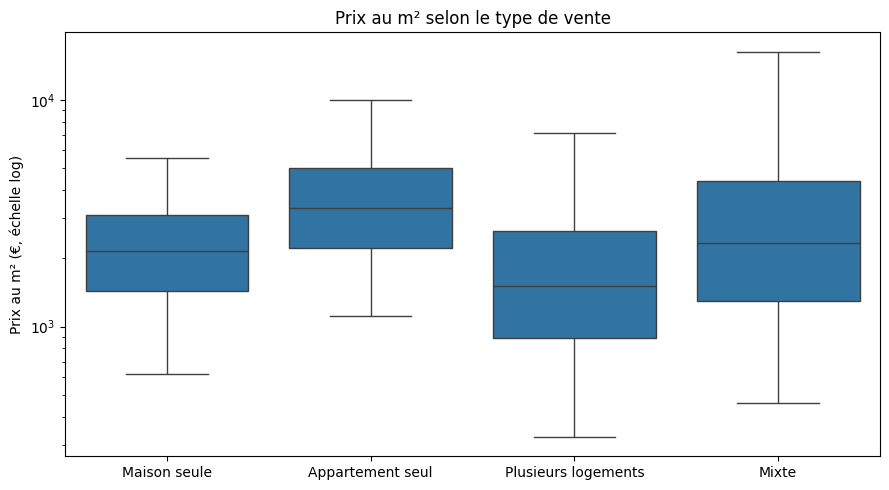

,count,25%,50%,75%,IQR / médiane
type_vente,,,,,
Appartement seul,362002.0,2216.216216,3341.463415,5000.000000,0.833103
Local commercial,0.0,NaN,NaN,NaN,NaN
Maison seule,463386.0,1428.571429,2153.846154,3114.985632,0.782978
Mixte,22435.0,1300.176678,2340.306122,4397.802198,1.323598
Plusieurs logements,44127.0,886.729560,1506.493506,2641.588050,1.164863
Sans logement,0.0,NaN,NaN,NaN,NaN


In [97]:
# Prix au m² selon le type de vente (ventes avec surface habitable)
ordre = ['Maison seule', 'Appartement seul', 'Plusieurs logements', 'Mixte']
fig, ax = plt.subplots(figsize=(9, 5))
sn.boxplot(data=ventes[ventes['type_vente'].isin(ordre)], x='type_vente', y='prix_m2',
            order=ordre, ax=ax, showfliers=False, whis=(5, 95))
ax.set_yscale('log')
ax.set_xlabel('')
ax.set_ylabel('Prix au m² (€, échelle log)')
ax.set_title('Prix au m² selon le type de vente')
plt.tight_layout()
plt.show()

# Dispersion chiffrée : écart interquartile relatif (IQR / médiane)
stats = ventes.groupby('type_vente')['prix_m2'].describe()[['count', '25%', '50%', '75%']]
stats['IQR / médiane'] = (stats['75%'] - stats['25%']) / stats['50%']
stats

**Constat :** la dispersion relative (IQR / médiane) est de 0,78 pour les maisons seules et 0,83 pour les appartements seuls, contre 1,16 pour les ventes de plusieurs logements et 1,32 pour les ventes mixtes. Le prix au m² de ces deux dernières catégories est peu interprétable, car le prix total couvre des biens hétérogènes.

In [98]:
# Périmètre retenu : ventes d'un seul logement, hors ventes ambiguës (voir 13.1 bis)
avant = len(ventes)
ventes = ventes[ventes['type_vente'].isin(['Maison seule', 'Appartement seul'])
                & ~ventes['doublon_ambigu']].copy()
print(f'Ventes conservées : {len(ventes)} ({len(ventes)/avant:.1%})')

Ventes conservées : 823258 (62.2%)


**Décision :** le périmètre retenu se limite aux ventes d'une seule maison ou d'un seul appartement, hors ventes ambiguës. Il reste **823 258 ventes** (62,2 % des ventes de nature Vente ou VEFA).

# analyse des valeurs aberantes

In [99]:
quantiles = [0, 0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999, 1]
ventes[["valeur_fonciere", "surface_bati", "prix_m2"]].quantile(quantiles)

,valeur_fonciere,surface_bati,prix_m2
0.000,1.500000e-01,0.0,1.379310e-03
0.001,9.000000e+02,10.0,1.250000e+01
0.010,1.900000e+04,18.0,2.777778e+02
0.050,5.000000e+04,26.0,7.626667e+02
0.500,1.870000e+05,77.0,2.586207e+03
0.950,5.902786e+05,157.0,8.050000e+03
0.990,1.175000e+06,220.0,1.255001e+04
0.999,3.320892e+06,337.0,2.500000e+04
1.000,2.575000e+08,1537.0,2.546587e+06


98 % des ventes sont entre 19 000 € et 1,2 M€ (médiane de 187 000 €), mais les extrêmes vont de 0,15 € à 257,5 M€. Le prix au m² va de 0,001 à 2,5 M€/m², alors que 98 % des ventes sont entre 278 et 12 550 €/m².

In [100]:
#Nombre de logements dont la surface rend le prix au m² peu fiable
print("Surface manquante :", ventes["surface_bati"].isna().sum())
print("Surface nulle :", (ventes["surface_bati"] == 0).sum())
print("Surface < 9 m² :", (ventes["surface_bati"] < 9).sum())
print("Surface > 1000 m² :", (ventes["surface_bati"] > 1000).sum())

Surface manquante : 0
Surface nulle : 74
Surface < 9 m² : 456
Surface > 1000 m² : 2


la surface est propre : aucune valeur manquante, 456 logements de moins de 9 m² (dont 74 à 0 m²) et 2 de plus de 1 000 m², soit 0,06 % des ventes.

In [101]:
import plotly.express as px
# on prend un échantillon de 50 000 ventes pour garder un graphique fluide ; random_state rend le tirage reproductible
echantillon = ventes.sample(50000, random_state=42)
# on applique l'échelle log sur les deux axes pour voir à la fois les petits et les gros montants
px.scatter(
    echantillon,
    x="surface_bati",
    y="valeur_fonciere",
    color="type_vente",
    log_x=True,
    log_y=True,
    opacity=0.3,
    title="Surface et prix des ventes",
    labels={"surface_bati": "Surface bâtie (m²)", "valeur_fonciere": "Valeur foncière (€)"},
)

le prix augmente avec la surface, comme attendu. On voit aussi une ligne de ventes à 1 € (c'est probablement des cessions symboliques), des points isolés entre 10 et 1 000 €, et quelques logements de 1 m² vendus 300 000 € (des probables erreurs de surface).

In [102]:
# Prix médian au m² de chaque département, trié du moins cher au plus cher
# on utilise observed=True pour ne garder que les départements présents
mediane_dep = ventes.groupby("code_departement", observed=True)["prix_m2"].median().sort_values()
# iloc[0] pour selectionner le premier élément le moins cher, iloc[-1] pour selectionner dernier le plus cher
print("Département le moins cher :", mediane_dep.index[0], round(mediane_dep.iloc[0]), "€/m²")
print("Département le plus cher :", mediane_dep.index[-1], round(mediane_dep.iloc[-1]), "€/m²")
print("Rapport :", round(mediane_dep.max() / mediane_dep.min(), 1))

px.bar(mediane_dep, title="Prix médian au m² par département")

Département le moins cher : 23 851 €/m²
Département le plus cher : 75 9692 €/m²
Rapport : 11.4


**Constat :** le prix médian au m² est 11,4 fois plus élevé à Paris (9 692 €/m²) que dans la Creuse (851 €/m²).

**Décision :** un seuil national n'a pas de sens, car 1 000 €/m² est un prix normal dans la Creuse mais suspect à Paris. Les seuils de prix au m² seront donc calculés par département et par type de bien.

#Application du filtre

In [103]:
avant = len(ventes)

# between(9, 1000) garde les surfaces comprises entre 9 et 1 000 m², bornes incluses
ventes = ventes[ventes["surface_bati"].between(9, 1000)]
print("Après le filtre de surface :", len(ventes))

# Un groupe = un département et un type de bien (maison ou appartement)
groupes = ventes.groupby(["code_departement", "type_vente"], observed=True)["prix_m2"]

# transform calcule le percentile de chaque groupe et le recopie sur chaque ligne du groupe
p01 = groupes.transform(lambda s: s.quantile(0.01))
p99 = groupes.transform(lambda s: s.quantile(0.99))

# Chaque vente est comparée aux seuils de son propre groupe
ventes = ventes[ventes["prix_m2"].between(p01, p99)]

print(f"Ventes retirées : {avant - len(ventes)} ({1 - len(ventes) / avant:.1%})")
print("Ventes restantes :", len(ventes))

Après le filtre de surface : 822800
Ventes retirées : 17074 (2.1%)
Ventes restantes : 806184


le filtre de surface retire 458 ventes, puis le filtre sur le prix au m² en retire 16 616. Au total, 17 074 ventes sont retirées (2,1 %) et il en reste 806 184


In [104]:
# Mêmes quantiles qu'avant le filtrage, pour comparer les resultats
ventes[["valeur_fonciere", "surface_bati", "prix_m2"]].quantile(quantiles)

,valeur_fonciere,surface_bati,prix_m2
0.000,5.480000e+02,9.0,8.087763
0.001,9.000000e+03,12.0,157.894737
0.010,2.700000e+04,18.0,414.564165
0.050,5.500000e+04,27.0,823.529412
0.500,1.878685e+05,77.0,2586.010753
0.950,5.750000e+05,156.0,7750.000000
0.990,1.078162e+06,219.0,11833.822627
0.999,2.493066e+06,330.0,17647.058824
1.000,2.050000e+07,903.0,58684.210526


**Constat :** après filtrage, 99,8 % des ventes ont un prix au m² entre 158 et 17 648 €/m², et la valeur foncière minimale passe de 0,15 € à 548 €. Il reste quelques valeurs extrêmes (8 €/m² au minimum, 58 684 €/m² au maximum), car les seuils sont calculés par département : le 1er percentile d'un département bon marché peut être très bas.

**Limite :** le choix du 1er et du 99e percentile retire 2 % des ventes de chaque groupe, même dans un département qui a très peu de valeurs aberrantes.

In [105]:
# Nouvel échantillon, tiré après le filtrage
echantillon = ventes.sample(50000, random_state=42)

px.scatter(
    echantillon,
    x="surface_bati",
    y="valeur_fonciere",
    color="type_vente",
    log_x=True,
    log_y=True,
    opacity=0.3,
    title="Surface et prix des ventes, après filtrage",
    labels={"surface_bati": "Surface bâtie (m²)", "valeur_fonciere": "Valeur foncière (€)"},
)

la ligne de ventes à 1 € et les logements de 1 m² ont disparu. Le nuage suit une tendance nette (le prix augmente avec la surface), avec les appartements surtout sur les petites surfaces et les maisons sur les grandes. Quelques points restent isolés en bas, comme une maison de 27 m² à 10 000 €.

#Choix de la variable cible

In [106]:
import numpy as np

# Le logarithme écrase les grandes valeurs pour rendre  symétrique la distribution de prix
ventes["log_valeur"] = np.log(ventes["valeur_fonciere"])

# skew() calcule l'asymétrie de chaque colonne
ventes[["valeur_fonciere", "log_valeur", "prix_m2"]].skew()

/tmp/ipykernel_2275/2237056387.py:4: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,0
valeur_fonciere,8.252498
log_valeur,-0.223528
prix_m2,2.288285


 la valeur foncière est très asymétrique (skew de 8,25), le prix au m² l'est moins (2,29), et le logarithme de la valeur foncière est presque symétrique (−0,22).

In [107]:
# Un histogramme par cible possible ; nbins = nombre de barres
px.histogram(ventes, x="valeur_fonciere", nbins=100, title="Valeur foncière (€)").show()
px.histogram(ventes, x="log_valeur", nbins=100, title="Logarithme de la valeur foncière").show()
px.histogram(ventes, x="prix_m2", nbins=100, title="Prix au m² (€)").show()

**Constat :** l'histogramme de la valeur foncière est écrasé à gauche par quelques ventes très chères. Celui du prix au m² est moins écrasé : la plupart des ventes sont entre 1 000 et 4 000 €/m², mais une longue traîne s'étire jusqu'à environ 58 000 €/m². Celui du logarithme de la valeur foncière a une forme de cloche, centrée autour de 12, soit environ 163 000 € (e¹²).

**Décision :** la cible retenue est le logarithme de la valeur foncière, car c'est la distribution la plus symétrique. Une cible très asymétrique pousse une régression linéaire à se concentrer sur les quelques ventes extrêmes.

**Conséquences :** valeur_fonciere et prix_m2 sont exclues des features, car elles servent à calculer la cible (data leakage). Les prédictions seront converties en euros avec np.exp pour calculer une erreur compréhensible (MAE en €).

#sauvegarde des données traités

In [108]:
# nous allons utiliser le format parquet cer il est plus rapide à lire qu'un CSV et conserve les types (dates, catégories)
ventes.to_parquet("clean_dvf_2025_ventes.parquet")
ventes.shape

(806184, 17)